# 03 — Baselines and linear regression

**Goal of this notebook:** find out how much of a phone's (log) price its listed specs explain, and how much extra each brand charges for the same specs, using ordinary linear regression.

Everything here uses the **training set only** (558 phones). Models are compared by **5-fold grouped cross-validation**: the training set is cut into 5 parts (all storage variants of a phone in the same part). Each part takes one turn as the validation set while the model is fitted on the other 4, and we report the mean ± standard deviation of the 5 scores. The test set stays locked until Phase 7.

**Metrics** (same for every model in the project):
- **R² on log price**: the share of the variation in log price that the model explains. 1 is perfect; 0 is no better than always predicting the average.
- **Median % error**: we turn the prediction back into rupees (`exp(prediction)`) and take the median of |predicted − actual| / actual. "Median" means half of the phones are predicted better than this.
- **MAE (₹)**: mean absolute error in rupees. It is dominated by expensive phones, where errors are large in rupees.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import KFold

from features import NUMERIC_FEATURES, CATEGORICAL_FEATURES
from split import load_train_test
from evaluate import price_metrics, grouped_cv_scores, summarise, pretty

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ae",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e0",
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
})
pd.set_option("display.width", 200)

train, test = load_train_test(include_web_lookup=True)              # main version (702 phones)
train_name, _ = load_train_test(include_web_lookup=False)           # robustness version (695 phones)
print("training phones:", len(train), "| name-only training phones:", len(train_name))
del test   # not used in this notebook

training phones: 558 | name-only training phones: 555


## 0. Why grouped cross-validation? A quick check
Phase 3 explained that a random split of rows lets storage variants of the same phone sit on both sides. Here we measure what that would do to a score, using Model B (defined below) on the training set: once with random 5-fold CV, once with grouped 5-fold CV.

In [2]:
CHIP_REF, BRAND_REF = "snapdragon_other", "Samsung"
NUM_TERMS = " + ".join(NUMERIC_FEATURES)
FORMULA_A = f"log_price ~ {NUM_TERMS} + C(chip_group, Treatment('{CHIP_REF}'))"
FORMULA_B = FORMULA_A + f" + C(brand, Treatment('{BRAND_REF}'))"

def replace_unseen(pred_rows, fit_rows):
    # A category that never appeared while fitting has no coefficient, so we treat it
    # as the reference category (no extra effect). This is rare: e.g. the single
    # 'other'-chip phone can only appear in one fold.
    out = pred_rows.copy()
    for col, ref in [("chip_group", CHIP_REF), ("brand", BRAND_REF)]:
        out.loc[~out[col].isin(fit_rows[col].unique()), col] = ref
    return out

def ols(formula):
    def fit_predict(fit_rows, pred_rows):
        model = smf.ols(formula, data=fit_rows).fit()
        return model.predict(replace_unseen(pred_rows, fit_rows))
    return fit_predict

random_folds = []
for fit_idx, val_idx in KFold(5, shuffle=True, random_state=42).split(train):
    fit_rows, val_rows = train.iloc[fit_idx], train.iloc[val_idx]
    random_folds.append(price_metrics(val_rows["log_price"], ols(FORMULA_B)(fit_rows, val_rows)))
random_folds = pd.DataFrame(random_folds)
grouped_folds = grouped_cv_scores(ols(FORMULA_B), train)
pretty([summarise(random_folds, "Model B, random folds"), summarise(grouped_folds, "Model B, grouped folds")])

,R² (log price),median % error,MAE (₹)
model,,,
"Model B, random folds",0.855 ± 0.011,18.8 ± 1.9,"11,578 ± 1,820"
"Model B, grouped folds",0.845 ± 0.018,18.2 ± 2.2,"11,757 ± 1,658"


**Takeaway:** random folds give R² 0.855 and grouped folds 0.845, so the optimistic bias from leaking storage variants is real but small here (about 1 R² point). Variants differ in storage, which is itself a big price driver, so a sibling in training does not simply give away the answer. The grouped scores also vary more between folds (± 0.018 vs ± 0.011), because each grouped fold contains genuinely new phones. We use grouped CV everywhere, because the question is how well we price **unseen** phones.

## 1. Baselines
A **baseline** is a deliberately simple prediction that any real model must beat. Without one, an R² of 0.8 has nothing to be compared against.
- **Baseline 1 — overall mean:** predict the training mean of log price for every phone. Its R² is about 0 by construction.
- **Baseline 2 — brand mean:** predict the mean log price of the phone's brand in the training folds. This shows how much brand *alone* tells us. A brand never seen while fitting gets the overall mean.

In [3]:
def mean_baseline(fit_rows, pred_rows):
    return np.full(len(pred_rows), fit_rows["log_price"].mean())

def brand_mean_baseline(fit_rows, pred_rows):
    brand_means = fit_rows.groupby("brand")["log_price"].mean()
    return pred_rows["brand"].map(brand_means).fillna(fit_rows["log_price"].mean()).to_numpy()

results = {}       # model name -> per-fold scores (main data)
results_name = {}  # same, name-only data
for name, fp in [("Baseline 1: overall mean", mean_baseline), ("Baseline 2: brand mean", brand_mean_baseline)]:
    results[name] = grouped_cv_scores(fp, train)
    results_name[name] = grouped_cv_scores(fp, train_name)
pretty([summarise(f, n) for n, f in results.items()])

,R² (log price),median % error,MAE (₹)
model,,,
Baseline 1: overall mean,-0.006 ± 0.005,59.1 ± 2.4,"29,797 ± 2,812"
Baseline 2: brand mean,0.366 ± 0.056,40.3 ± 3.1,"22,181 ± 2,706"


**Takeaway:** always predicting the average is off by a median of 59 % (R² ≈ 0). Knowing only the brand already explains 37 % of the variation in log price (median error 40 %). Every model below must clearly beat 0.37.

## 2. Model A — "hardware value": specs + chip family, no brand
**Ordinary least squares (OLS)** linear regression finds the coefficients *b* that minimise the sum of squared errors of

log_price = b₀ + b₁·log2_ram + b₂·log2_storage + … + (chip-family effects).

The chip enters through `chip_group`, which is `chip_family` with Apple A-series and Snapdragon 8 chips merged into one flagship group (the reason is shown in section 3). It is a **categorical** feature, so it enters as **dummy variables** (one 0/1 column per group). One group is left out as the **reference**, here `snapdragon_other`, the largest group. Each chip coefficient is then the difference from a Snapdragon-other phone with the same specs. Leaving one out is required: the dummies of all families always add up to 1, which would duplicate the intercept.

Model A has **no brand**. It answers "what would a typical phone with this hardware cost?", which we call the phone's *hardware value*.

We use **statsmodels** for the coefficient table, because it reports a **95 % confidence interval** for every coefficient: the range of values compatible with the data. If we repeated the data collection many times, about 95 % of intervals built this way would contain the true value.

In [4]:
for name, formula in [("Model A: specs + chip", FORMULA_A)]:
    results[name] = grouped_cv_scores(ols(formula), train)
    results_name[name] = grouped_cv_scores(ols(formula), train_name)

model_a = smf.ols(FORMULA_A, data=train).fit()

# How to read each coefficient in plain words: the change in the feature we describe
UNIT = {"log2_ram": (1, "doubling RAM"), "log2_storage": (1, "doubling storage"),
        "battery_mah": (1000, "+1000 mAh battery"), "screen_in": (0.5, "+0.5 inch screen"),
        "main_back_mp": (10, "+10 MP main camera"), "front_mp": (10, "+10 MP front camera"),
        "n_back_cameras": (1, "+1 back camera"), "weight_g": (10, "+10 g weight"), "year": (1, "+1 year newer")}

def nice_name(term):
    if term.startswith("C(chip_"): return "chip: " + term.split("[T.")[1].rstrip("]")
    if term.startswith("C(brand"): return "brand: " + term.split("[T.")[1].rstrip("]")
    return term

def coef_table(fit):
    ci = fit.conf_int()
    rows = []
    for term in fit.params.index:
        if term == "Intercept":
            continue
        step, meaning = UNIT.get(term, (1, "vs reference"))
        b, lo, hi = fit.params[term] * step, ci.loc[term, 0] * step, ci.loc[term, 1] * step
        rows.append({"term": nice_name(term), "change": meaning, "coef (per change)": b,
                     "% price effect": 100 * (np.exp(b) - 1),
                     "95% CI low %": 100 * (np.exp(lo) - 1), "95% CI high %": 100 * (np.exp(hi) - 1),
                     "p-value": fit.pvalues[term]})
    return pd.DataFrame(rows).set_index("term")

table_a = coef_table(model_a)
table_a.to_csv("../results/ols_model_a_coefficients.csv")
print(f"Model A fitted on {int(model_a.nobs)} training phones, in-sample R² = {model_a.rsquared:.3f}")
table_a.round(3)

Model A fitted on 558 training phones, in-sample R² = 0.799


,change,coef (per change),% price effect,95% CI low %,95% CI high %,p-value
term,,,,,,
chip: dimensity_high,vs reference,0.226,25.417,10.050,42.930,0.001
chip: dimensity_other,vs reference,-0.133,-12.437,-20.808,-3.181,0.010
chip: exynos,vs reference,0.269,30.843,14.310,49.767,0.000
chip: flagship_sd8_or_apple,vs reference,0.610,83.998,65.076,105.088,0.000
chip: helio,vs reference,-0.410,-33.643,-40.940,-25.444,0.000
chip: kirin,vs reference,0.692,99.831,46.064,173.388,0.000
chip: tensor,vs reference,0.560,75.047,37.319,123.141,0.000
chip: unisoc,vs reference,-0.601,-45.166,-54.437,-34.009,0.000
log2_ram,doubling RAM,0.240,27.104,16.455,38.727,0.000


**How to read the table.** Because the target is log price, a coefficient *b* is a **multiplicative** effect: the change multiplies the price by exp(*b*), i.e. changes it by (exp(*b*) − 1) × 100 %. For `log2_ram` one unit means *doubling* RAM, so "% price effect" is the price change for doubling RAM with every other spec (and the chip family) held fixed. For other numeric specs we show a more readable step (+1000 mAh, +10 MP, …), which simply multiplies *b* by that step. The **p-value** is the probability of seeing an estimate this far from zero if the true effect were zero. Small values (below 0.05) mean the data clearly shows an effect.

**Takeaway (Model A, hardware only).** Cross-validated R² is about 0.77 (table in section 3), so specs and chip alone explain most of the price variation. The in-sample R², 0.80 on the training data, is slightly higher, as fitted data always is. In plain words, with all other specs held fixed:
- **Doubling RAM** goes with **+27 %** price (95 % CI 16 % to 39 %), and **doubling storage** with **+23 %** (17 % to 29 %).
- **Chip group** matters a lot. A flagship chip (Snapdragon 8 or Apple A) adds **+84 %** over a mid-range Snapdragon, while budget chips cut price (Helio −34 %, Unisoc −45 %). Tensor (+75 %) and Kirin (+100 %) look valuable too, but those chips are used by only one brand each (Google, Huawei), so here they partly stand in for the brand.
- **Weight** +12 % per 10 g (premium materials, foldables) and **launch year** +7 % per year.
- **Camera megapixels** and the **number of back cameras** have no detectable effect (all p > 0.5, intervals include 0).
- **Battery** has a *negative* coefficient: −31 % per extra 1000 mAh. This is not "batteries make phones cheaper". Among phones with the *same* RAM, storage, chip, weight, screen and year, the ones with a bigger battery tend to be budget "battery champion" models, while flagships stay slim. A coefficient describes an association **holding the other features fixed**, not a cause.
- **Screen size** is slightly negative here (−10 % per 0.5 inch), which is also implausible as a cause. Section 5 shows that screen and weight are entangled, and the sign flips in Model B.

## 3. Model B — "brand-aware": specs + chip family + brand
Same as Model A plus brand dummies, with **Samsung as the reference brand** (it has many phones across all price levels). Each brand coefficient *b* now means: *for the same specs and chip family, this brand's phones cost (exp(b) − 1) × 100 % more (or less) than a Samsung.* That is our first estimate of the **brand premium**.

### First, a problem: Apple's chip and Apple's brand are the same column
With the original `chip_family`, every Apple phone has an `apple_a` chip and no other brand does. So the `apple_a` dummy and the `Apple` brand dummy are **identical columns**. Then XᵀX has an eigenvalue of exactly 0 (a direction in which the data does not vary at all), its condition number is infinite, and the OLS solution is not unique: any split of Apple's extra price between "chip" and "brand" fits equally well. statsmodels does not stop with an error. It silently picks one split (using a pseudo-inverse), so the numbers look normal but mean nothing.

In [5]:
formula_bad = FORMULA_B.replace("chip_group", "chip_family")
bad = smf.ols(formula_bad, data=train).fit()
X_bad = pd.DataFrame(bad.model.exog, columns=bad.model.exog_names).drop(columns="Intercept")
Z = (X_bad - X_bad.mean()) / X_bad.std(ddof=0)
eig = np.linalg.eigvalsh(Z.T @ Z)
print(f"smallest eigenvalue of XᵀX: {eig.min():.2e}   ->  condition number {eig.max() / max(eig.min(), 1e-300):.1e}")
print("columns 'chip: apple_a' and 'brand: Apple' identical:",
      bool((X_bad["C(chip_family, Treatment('snapdragon_other'))[T.apple_a]"] == X_bad["C(brand, Treatment('Samsung'))[T.Apple]"]).all()))
print(f"coefficient chip apple_a = {bad.params.filter(like='apple_a').iloc[0]:.3f},  brand Apple = {bad.params.filter(like='T.Apple').iloc[0]:.3f}  (an arbitrary 50/50 split)")

smallest eigenvalue of XᵀX: -5.48e-13   ->  condition number 2.5e+303
columns 'chip: apple_a' and 'brand: Apple' identical: True
coefficient chip apple_a = 0.504,  brand Apple = 0.504  (an arbitrary 50/50 split)


/tmp/ipykernel_20549/2313758657.py:2: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  bad = smf.ols(formula_bad, data=train).fit()


**Our fix:** in `chip_group` we merge Apple A-series chips with flagship Snapdragon 8 chips (both are the top chip of their generation; launch year is in the model separately). The Apple brand coefficient then means "how much more an iPhone costs than a phone with a flagship chip and the same specs". This is an **assumption**, and Apple's premium depends on it. If Apple's chips are worth more than a flagship Snapdragon, part of what we call "brand premium" is really chip value. The same issue is milder for Google (`tensor` is used only by Google, but Google also sold Snapdragon phones) and Huawei (`kirin`, inside "Other"), which is why those coefficients will have wide intervals.

In [6]:
results["Model B: specs + chip + brand"] = grouped_cv_scores(ols(FORMULA_B), train)
results_name["Model B: specs + chip + brand"] = grouped_cv_scores(ols(FORMULA_B), train_name)

model_b = smf.ols(FORMULA_B, data=train).fit()
table_b = coef_table(model_b)
table_b.to_csv("../results/ols_model_b_coefficients.csv")
print(f"Model B fitted on {int(model_b.nobs)} training phones, in-sample R² = {model_b.rsquared:.3f}")
table_b.round(3)

Model B fitted on 558 training phones, in-sample R² = 0.873


,change,coef (per change),% price effect,95% CI low %,95% CI high %,p-value
term,,,,,,
chip: dimensity_high,vs reference,0.225,25.183,12.189,39.683,0.000
chip: dimensity_other,vs reference,-0.116,-10.958,-18.138,-3.149,0.007
chip: exynos,vs reference,0.096,10.065,-5.458,28.137,0.216
chip: flagship_sd8_or_apple,vs reference,0.463,58.823,43.779,75.441,0.000
chip: helio,vs reference,-0.270,-23.652,-31.290,-15.165,0.000
chip: kirin,vs reference,-0.226,-20.249,-45.128,15.909,0.235
chip: tensor,vs reference,0.003,0.252,-25.669,35.212,0.987
chip: unisoc,vs reference,-0.402,-33.114,-43.245,-21.174,0.000
brand: Apple,vs reference,0.545,72.528,47.547,101.738,0.000


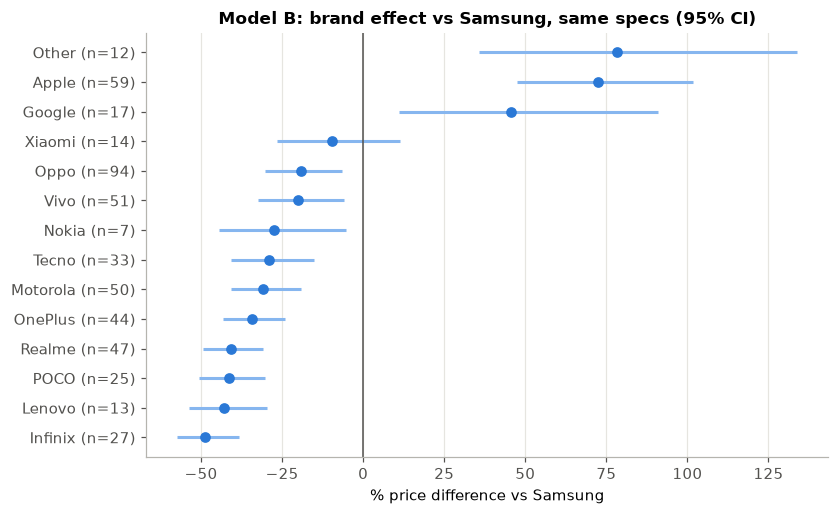

In [7]:
brand_rows = table_b[table_b.index.str.startswith("brand:")].sort_values("% price effect")
n_train = train["brand"].value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(brand_rows))
ax.errorbar(brand_rows["% price effect"], y,
            xerr=[brand_rows["% price effect"] - brand_rows["95% CI low %"], brand_rows["95% CI high %"] - brand_rows["% price effect"]],
            fmt="o", color=BLUE, ecolor="#86b6ef", elinewidth=2, capsize=0, markersize=6)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [f"{b.split(': ')[1]} (n={n_train[b.split(': ')[1]]})" for b in brand_rows.index])
ax.set(title="Model B: brand effect vs Samsung, same specs (95% CI)", xlabel="% price difference vs Samsung")
ax.grid(axis="y", visible=False)
fig.savefig("../results/fig03_model_b_brand_effects.png")
plt.show()

**Takeaway (Model B, brand premiums vs Samsung, same specs):**
- Only three brands charge **more** than Samsung: **Apple +73 %** (95 % CI 48 % to 102 %), **Google +46 %** (11 % to 91 %) and **"Other" +78 %** (36 % to 134 %; Sony and Huawei flagships, only 12 training phones, hence the very wide interval).
- **Xiaomi** (−10 %) is the only brand whose interval includes 0: for the same specs, we cannot tell it apart from Samsung.
- All other brands are clearly cheaper for the same specs, from Oppo and Vivo (−19 %, −20 %) to Realme, POCO, Lenovo (about −41 to −43 %) and **Infinix −49 %**.
- Samsung is itself a premium-priced reference, so most brands appear "cheaper". Phase 8 re-expresses premiums relative to the **average** brand.

Adding brand also changes the spec and chip coefficients. Tensor drops from +75 % to 0 % and Kirin from +100 % to −20 % (not significant): in Model A those chips were mostly carrying the Google and Huawei brand effect. RAM rises to +48 % and storage falls to +10 % per doubling; section 5 explains why these two move around.

### Cross-validated comparison so far

In [8]:
pretty([summarise(f, n) for n, f in results.items()])

,R² (log price),median % error,MAE (₹)
model,,,
Baseline 1: overall mean,-0.006 ± 0.005,59.1 ± 2.4,"29,797 ± 2,812"
Baseline 2: brand mean,0.366 ± 0.056,40.3 ± 3.1,"22,181 ± 2,706"
Model A: specs + chip,0.773 ± 0.039,23.3 ± 1.7,"14,273 ± 2,048"
Model B: specs + chip + brand,0.845 ± 0.018,18.2 ± 2.2,"11,757 ± 1,658"


**Takeaway:** specs + chip lift R² from 0.37 (brand only) to **0.773**, and adding brand lifts it further to **0.845**, cutting the median price error from 23.3 % to **18.2 %**. So specs explain most of the price, and brand adds a clear, measurable extra. These numbers are higher than the pilot's (≈ 0.6 specs-only, ≈ 0.78 with brand) because our "specs-only" Model A already includes the chip group, which is very informative.

## 4. Diagnostics for Model B
OLS coefficients and their confidence intervals rely on some assumptions about the **residuals** (actual − predicted log price on the training data):
1. **Linearity:** no curved pattern in residuals vs fitted values.
2. **Constant variance** (*homoscedasticity*): the spread of residuals does not grow or shrink with the fitted value.
3. **Normality:** residuals roughly follow a bell curve. A **Q-Q plot** compares the sorted residuals with what a normal distribution would give; points on the straight line mean "normal".
4. **Independence:** one phone's error tells us nothing about another's. Storage variants of the same phone break this a little. That makes the confidence intervals somewhat too narrow, but it does not bias the coefficients.

/tmp/ipykernel_20549/2177730609.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2].boxplot([resid[train["brand"] == b] for b in order], vert=False, widths=0.6, patch_artist=True,


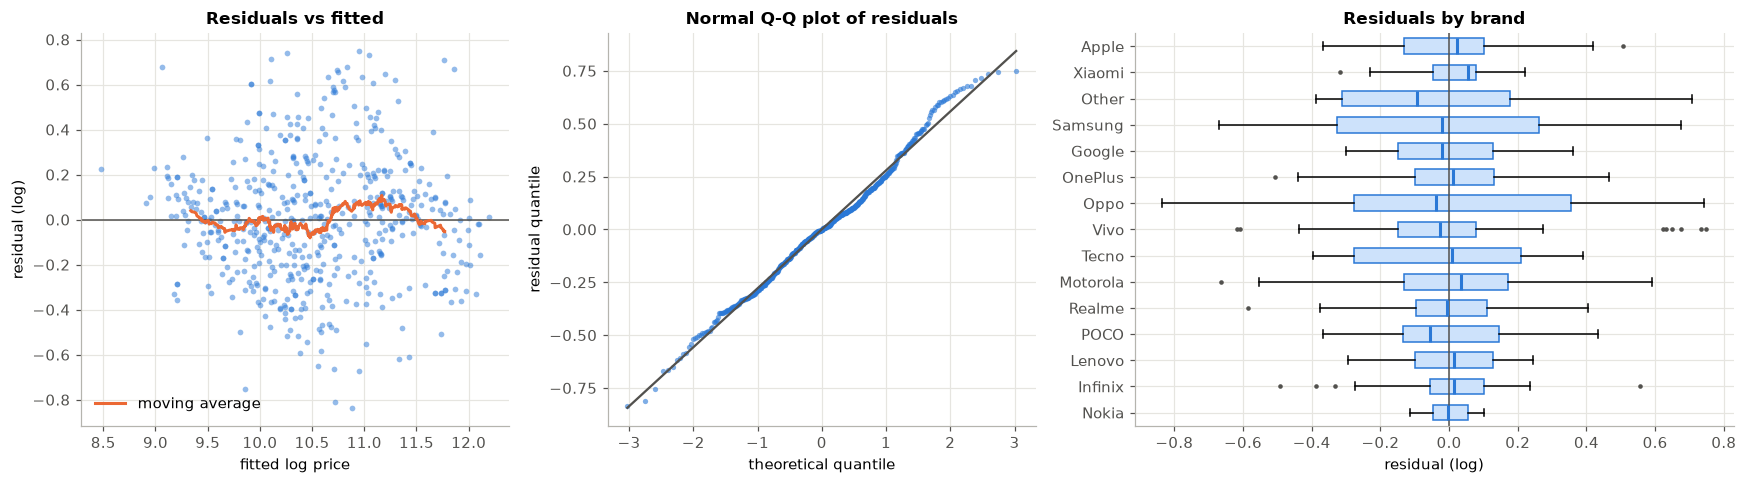

residual std: 0.279  (a residual of 0.1 is about a 10 % price error)
skewness: 0.18, excess kurtosis: 0.15

Largest residuals:
     brand      Model Name  price_inr     resid
387  Oppo    K10 5G 256GB    22999.0 -0.835861
372  Oppo      K11x 256GB    20000.0 -0.811643
368  Oppo    A49 5G 128GB     8999.0 -0.753199
199  Vivo      X200 128GB   119999.0  0.748937
304  Oppo  K12 Plus 256GB    59999.0  0.742088
200  Vivo      X200 256GB   129999.0  0.733276


In [9]:
resid, fitted = model_b.resid, model_b.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.4]})

axes[0].scatter(fitted, resid, s=14, color=BLUE, alpha=0.5, linewidths=0)
axes[0].axhline(0, color=MUTED, linewidth=1)
smooth = pd.Series(resid.values, index=fitted.values).sort_index().rolling(60, center=True).mean()
axes[0].plot(smooth.index, smooth.values, color=ORANGE, linewidth=2, label="moving average")
axes[0].set(title="Residuals vs fitted", xlabel="fitted log price", ylabel="residual (log)")
axes[0].legend(frameon=False)

(osm, osr), (slope, intercept, _) = stats.probplot(resid, dist="norm")
axes[1].scatter(osm, osr, s=12, color=BLUE, alpha=0.6, linewidths=0)
axes[1].plot(osm, slope * osm + intercept, color=MUTED, linewidth=1.5)
axes[1].set(title="Normal Q-Q plot of residuals", xlabel="theoretical quantile", ylabel="residual quantile")

order = train.groupby("brand")["log_price"].median().sort_values().index
axes[2].boxplot([resid[train["brand"] == b] for b in order], vert=False, widths=0.6, patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none"))
axes[2].set_yticks(range(1, len(order) + 1), order)
axes[2].axvline(0, color=MUTED, linewidth=1)
axes[2].set(title="Residuals by brand", xlabel="residual (log)")
fig.tight_layout()
fig.savefig("../results/fig03_model_b_diagnostics.png")
plt.show()

print(f"residual std: {resid.std():.3f}  (a residual of 0.1 is about a 10 % price error)")
print(f"skewness: {stats.skew(resid):.2f}, excess kurtosis: {stats.kurtosis(resid):.2f}")
largest = train.assign(resid=resid).loc[resid.abs().sort_values(ascending=False).index[:6],
                                        ["brand", "Model Name", "price_inr", "resid"]]
print("\nLargest residuals:\n", largest.to_string())

**Takeaway — do the linear assumptions look reasonable?** Mostly yes.
- **Linearity:** the moving average of the residuals stays within about ±0.1 of zero across the whole range, a slight wave but no strong curve.
- **Constant variance:** the vertical spread looks similar for cheap and expensive phones.
- **Normality:** the Q-Q points lie close to the line (skewness 0.18, excess kurtosis 0.15), with a slightly heavier upper tail (a few phones priced well above prediction).
- **By brand:** medians are near zero (brand dummies absorb each brand's average), but spreads differ. Samsung and Oppo have the widest spread because both sell everything from budget phones to foldables, and one brand premium cannot fit all their product lines. The largest misses are Oppo's K-series and A49 (about 55 % *below* prediction) and the Vivo X200 (about twice its predicted price). This hints at interactions (a brand's premium depending on the tier), which tree models can capture.
- **Independence** is mildly broken by storage variants, so the confidence intervals above are somewhat too narrow. Phase 8 uses a grouped bootstrap to get more honest intervals.

The residual standard deviation is 0.28 on the log scale, i.e. a typical in-sample error of roughly ±30 % in price.

## 5. Multicollinearity: condition number and VIF
When features are strongly correlated, many different combinations of coefficients fit the data almost equally well, so the individual coefficients become unstable.

**Condition number (as in lectures).** We **standardise** each feature (subtract its mean, divide by its standard deviation) so that units do not matter, form XᵀX, and compute its **eigenvalues** λ. Each eigenvalue measures how much the data varies along one direction (an eigenvector, i.e. a combination of features). A tiny eigenvalue means a combination of features that barely varies, so the data says almost nothing about the coefficients along that direction. Their variance is proportional to 1/λ. The condition number is λ_max / λ_min. Values in the tens are harmless, and values above about 100–1000 signal trouble. (Note: `numpy.linalg.cond(X)` gives the square root of this ratio.)

**VIF (variance inflation factor).** For feature *j*, regress it on all the other features and get R²ⱼ. Then VIF = 1 / (1 − R²ⱼ). It says how many times larger the variance of coefficient *j* is than it would be with uncorrelated features (its standard error is √VIF times larger). VIF ≈ 1 means no problem, and above about 5–10 is the usual warning level.

In [10]:
def standardised(X):
    X = X.astype(float)
    return (X - X.mean()) / X.std(ddof=0)

def eigen_report(X, label):
    Z = standardised(X)
    eigvals, eigvecs = np.linalg.eigh(Z.T @ Z)
    print(f"{label}: {Z.shape[1]} columns, λ_max = {eigvals.max():.1f}, λ_min = {eigvals.min():.2f}, "
          f"condition number λ_max/λ_min = {eigvals.max() / eigvals.min():.1f}")
    return eigvals, pd.DataFrame(eigvecs, index=X.columns)

# (a) the 9 numeric features alone
eig_num, vec_num = eigen_report(train[NUMERIC_FEATURES], "Numeric features")
# (b) Model B's full design matrix (numeric + chip dummies + brand dummies, intercept removed)
design_b = pd.DataFrame(model_b.model.exog, columns=[nice_name(c) for c in model_b.model.exog_names]).drop(columns="Intercept")
eig_b, vec_b = eigen_report(design_b, "Model B design   ")

print("\nEigenvalues of the numeric-feature XᵀX (smallest first):", np.round(eig_num, 1))
print("\nThe eigenvector of the SMALLEST eigenvalue (numeric features), i.e. the least-determined direction:")
print(vec_num[0].round(2).sort_values(key=abs, ascending=False).to_string())
print("\nModel B design: largest loadings of its smallest-eigenvalue direction:")
print(vec_b[0].round(2).sort_values(key=abs, ascending=False).head(6).to_string())

Numeric features: 9 columns, λ_max = 2079.0, λ_min = 121.30, condition number λ_max/λ_min = 17.1
Model B design   : 31 columns, λ_max = 2373.3, λ_min = 25.05, condition number λ_max/λ_min = 94.7

Eigenvalues of the numeric-feature XᵀX (smallest first): [ 121.3  139.7  156.5  245.5  374.   412.3  656.5  837.2 2079. ]

The eigenvector of the SMALLEST eigenvalue (numeric features), i.e. the least-determined direction:
screen_in         0.53
weight_g         -0.49
log2_ram         -0.41
log2_storage      0.40
year             -0.31
battery_mah       0.14
main_back_mp      0.13
front_mp         -0.13
n_back_cameras    0.02

Model B design: largest loadings of its smallest-eigenvalue direction:
brand: Oppo        0.38
brand: Vivo        0.35
brand: Motorola    0.32
brand: Tecno       0.29
brand: Realme      0.28
brand: OnePlus     0.26


In [11]:
def vif_table(X):
    Xc = X.astype(float).assign(const=1.0)
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(X.shape[1])], index=X.columns)

vif = pd.DataFrame({
    "VIF (numeric only)": vif_table(train[NUMERIC_FEATURES]),
    "VIF (in Model B, with chip + brand)": vif_table(design_b)[NUMERIC_FEATURES],
}).round(2).sort_values("VIF (in Model B, with chip + brand)", ascending=False)
vif.to_csv("../results/vif.csv")
vif

,VIF (numeric only),"VIF (in Model B, with chip + brand)"
log2_ram,2.86,4.80
n_back_cameras,1.17,4.34
screen_in,2.88,4.26
weight_g,2.22,3.95
battery_mah,2.26,3.69
year,2.03,3.31
log2_storage,2.21,2.80
front_mp,1.69,2.76
main_back_mp,1.75,2.03


**Takeaway — collinearity is moderate, not severe, but it matters for RAM vs storage.**
- Numeric features alone: condition number **17** (eigenvalues from 121 to 2079), and all VIFs **below 3**. Inside Model B (with chip and brand dummies) the VIFs rise to at most **4.8** (RAM), still below the usual warning level of 5–10. RAM's standard error is about √4.8 ≈ 2.2 times what it would be with uncorrelated features.
- The **least-determined direction** (smallest eigenvalue) loads on screen vs weight (0.53 and 0.49, with opposite signs) and **RAM vs storage (0.41 and 0.40, with opposite signs)**. In words: "more RAM but less storage" and "heavier but smaller screen" are combinations the data barely contains, so it cannot say much about how price changes along them.
- That is exactly why the **split** between RAM and storage is unstable: Model A says RAM +27 % / storage +23 %, while Model B says RAM +48 % / storage +10 %. Their **combined** effect (doubling both) is much more stable: +56 % in A and +63 % in B. The same instability explains the screen coefficient flipping sign (−10 % in A, +10 % in B).
- Model B's full design matrix has condition number **95** after merging the Apple chip into the flagship group (before, it was effectively infinite: XᵀX was singular). Its weakest direction is all the brand dummies moving together, i.e. the overall level of non-Samsung brands relative to the intercept. Differences *between* brands are better determined than each brand's gap to Samsung.

Ridge regression (next notebook) is designed for exactly this situation: it shrinks the coefficients along these weakly determined directions.

## 6. Robustness: name-only data vs data with the 7 web-lookup phones
All of the above used the 558 training phones including the 3 web-lookup phones that fell into the training set. Here we repeat the cross-validation and the key coefficients on the name-only training data (555 phones).

In [12]:
compare = pd.concat({
    "with web lookup": pretty([summarise(f, n) for n, f in results.items()]),
    "name-only": pretty([summarise(f, n) for n, f in results_name.items()]),
}, axis=1)
compare.to_csv("../results/cv_phase4_robustness.csv")
compare

with web lookup                                      name-only                               
                               R² (log price) median % error         MAE (₹)  R² (log price) median % error         MAE (₹)
model                                                                                                                      
Baseline 1: overall mean       -0.006 ± 0.005     59.1 ± 2.4  29,797 ± 2,812  -0.006 ± 0.005     59.2 ± 2.5  29,891 ± 2,825
Baseline 2: brand mean          0.366 ± 0.056     40.3 ± 3.1  22,181 ± 2,706   0.376 ± 0.055     39.7 ± 3.6  22,143 ± 2,744
Model A: specs + chip           0.773 ± 0.039     23.3 ± 1.7  14,273 ± 2,048   0.774 ± 0.037     23.4 ± 1.9  14,309 ± 1,993
Model B: specs + chip + brand   0.845 ± 0.018     18.2 ± 2.2  11,757 ± 1,658   0.846 ± 0.016     17.8 ± 2.0  11,750 ± 1,666

In [13]:
model_b_name = smf.ols(FORMULA_B, data=train_name).fit()
model_a_name = smf.ols(FORMULA_A, data=train_name).fit()
key = ["log2_ram", "log2_storage", "brand: Infinix", "brand: Apple", "brand: Xiaomi"]
side_by_side = pd.DataFrame({
    "Model A % (with lookup)": coef_table(model_a)["% price effect"],
    "Model A % (name-only)": coef_table(model_a_name)["% price effect"],
    "Model B % (with lookup)": coef_table(model_b)["% price effect"],
    "Model B % (name-only)": coef_table(model_b_name)["% price effect"],
}).reindex(key).round(1)
side_by_side

,Model A % (with lookup),Model A % (name-only),Model B % (with lookup),Model B % (name-only)
term,,,,
log2_ram,27.1,26.9,48.4,49.6
log2_storage,22.5,22.3,10.0,9.3
brand: Infinix,NaN,NaN,-48.6,-48.5
brand: Apple,NaN,NaN,72.5,73.9
brand: Xiaomi,NaN,NaN,-9.5,-10.5


**Takeaway:** the 7 web-lookup phones make no practical difference. Cross-validated R² differs by only 0.001 for both Model A and Model B. The key coefficients move by at most 1.4 percentage points (Apple +72.5 % vs +73.9 %, RAM doubling +48.4 % vs +49.6 %), and the Infinix premium, the brand all 7 phones belong to, is unchanged (−48.6 % vs −48.5 %).

In [14]:
summary_rows = [summarise(f, n) for n, f in results.items()]
pd.DataFrame(summary_rows).to_csv("../results/cv_phase4.csv", index=False)
print("Saved results/cv_phase4.csv")

Saved results/cv_phase4.csv


## Summary
| model | grouped CV R² | median % error |
|---|---|---|
| Baseline 1: overall mean | 0.00 | 59.1 % |
| Baseline 2: brand mean | 0.37 | 40.3 % |
| Model A: specs + chip | 0.773 | 23.3 % |
| Model B: specs + chip + brand | 0.845 | 18.2 % |

- Specs explain most of the price; brand adds a clear extra (R² +0.07, median error −5 points).
- With the same specs, Apple (+73 %), Google (+46 %) and the Sony/Huawei "Other" group (+78 %) charge more than Samsung. Infinix, Lenovo, POCO and Realme charge 40–50 % less.
- RAM and storage both matter, but how their joint effect is split between them is unstable (moderate collinearity). Camera megapixels do not matter once other specs are known.
- Decision made here: Apple A-series chips are grouped with flagship Snapdragon chips (`chip_group`), because otherwise the Apple brand and Apple chip columns are identical and the brand premium cannot be estimated.